# Assignment 1: MNIST anomaly detection with an autoencoder

This is the **PyTorch + PyTorch Lightning** variant of the assignment: the model is written with plain PyTorch
modules (`torch.nn`), and trained with [PyTorch Lightning](https://lightning.ai/docs/pytorch/stable/).

The only difference in the submission is the model file: instead of `model.keras` and `architecture.json`,
this notebook saves `model.pt2` (the model exported with `torch.export`) and `model_summary.txt`.

In [2]:
# In this assingnment, we will be using Pandas dataframes
# to read, transform, and store MNIST images. Make sure
# you are familiar with its API:
# https://pandas.pydata.org/pandas-docs/stable/

import pandas as pd

In [4]:
# Enter here the Dataset ID that you have received in the spreadsheet.
# Make sure that you use the ID that was assigned to you,
# otherwise your submission will be graded against the wrong images.
dataset_id = '20261029-062502_c4806367139f99116fb0e9005efb1aea'

# Assignment datasets are stored in an AWS S3 bucket. The following code
# downloads your dataset (~60MB) directly into RAM. Optionally,
# you can save the datasets to the local disk, but that's really not required.
# Read with the AWS credentials of your SageMaker space (the bucket is not public)
prefix = f's3://danylo-ucla/app/storage/mnist/jobs/transform_repack/{dataset_id}'

# The train dataframe contains only normal images: handwritten digits.
# Use it to train your model.
train_X = pd.read_parquet(f'{prefix}/train_x.parquet')

# In the validate and test dataframes, 75% of the images are anomalies
# (corrupted digits, or images that are not digits at all), and 25% are normal digits.
# Use them to select and evaluate your model, respectively.
validate_X = pd.read_parquet(f'{prefix}/validate_x.parquet')
test_X = pd.read_parquet(f'{prefix}/test_x.parquet')

# This is the segment of the dataset that will be graded in this assignment.
# It has the same mix of normal images and anomalies as validate and test, but no labels.
# Your model has to assign an anomaly score to each image, and you have to submit these scores.
score_X = pd.read_parquet(f'{prefix}/score_x.parquet')

# These are the labels corresponding to each image in the dataset.
# train_y has the digit of each image.
# validate_y and test_y have the following columns:
#   is_anomaly -- 1 if the image is an anomaly, 0 if it is a normal digit (this is what you predict)
#   anomaly_family, anomaly_type -- the kind of anomaly ('none' for normal images)
#   digit -- the digit that the image was made from (-1 if it is not a digit)
# Use the labels to select your model and to analyze which anomalies your model
# has more or less problems with. The labels should not be used to train the model itself:
# the model has to learn what normal images look like from the train dataframe only.
train_y = pd.read_parquet(f'{prefix}/train_y.parquet')
validate_y = pd.read_parquet(f'{prefix}/validate_y.parquet')
test_y = pd.read_parquet(f'{prefix}/test_y.parquet')

In [ ]:
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'retina'

In [6]:
import numpy as np

# The share of anomalies in the validate dataframe,
# and how many images there are of each kind of anomaly.
print('Anomaly rate:', validate_y['is_anomaly'].mean())
validate_y.groupby(['anomaly_family', 'anomaly_type']).size()

Anomaly rate: 0.75


anomaly_family  anomaly_type  
geometric       elastic            337
                shear              315
                shift              358
                zoom               351
noise           gaussian_noise     324
                patch_noise        352
                salt_pepper        333
                speckle            373
none            none              1750
occlusion       cutout             241
                letter             311
                mashup             328
                strokes            317
photometric     background         228
                blur               205
                invert             223
                low_contrast       216
                thicken            211
                thin               227
dtype: int64

In [7]:
# Just as in the lecture slides, the input matrix
# has row vectors that hold pixels of a single 28x28 image.
# Note that the column vectors are individual locations on
# the 28x28 grid, but flattened in a row-major way (28x28=784).
train_X.shape

(49000, 784)

In [8]:
example_id = 1

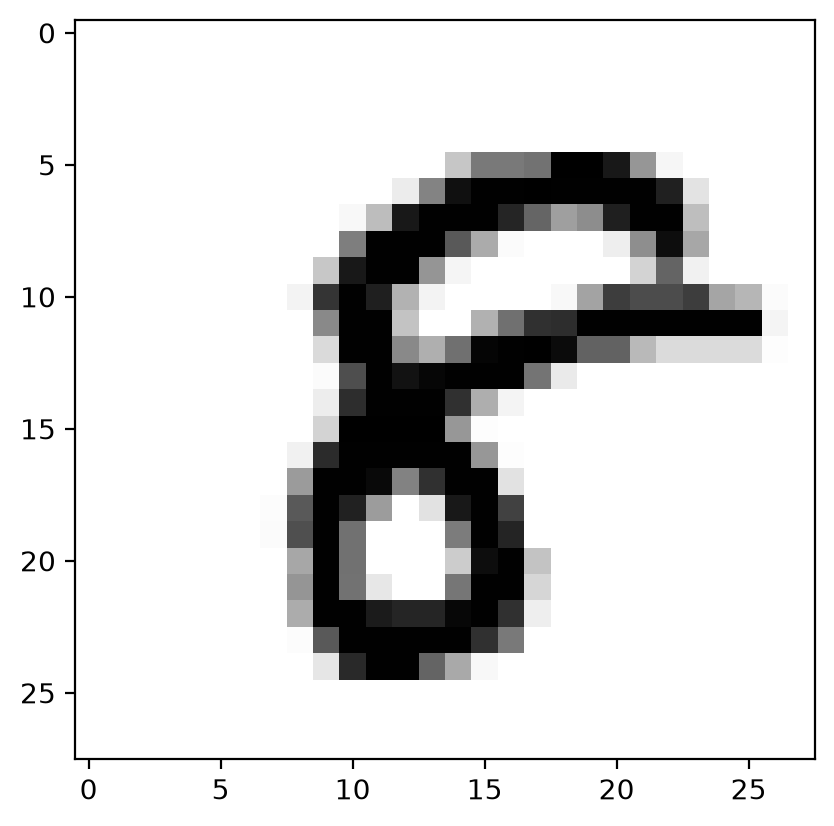

In [9]:
# Let's select a normal image from the train dataframe
image_pixels = train_X.iloc[example_id]

# In order to plot an image, you need to reshape
# the flattened array back into a 28x28 grid.
image_pixels = image_pixels.values.reshape(28, 28)

plt.imshow(image_pixels, cmap='binary')

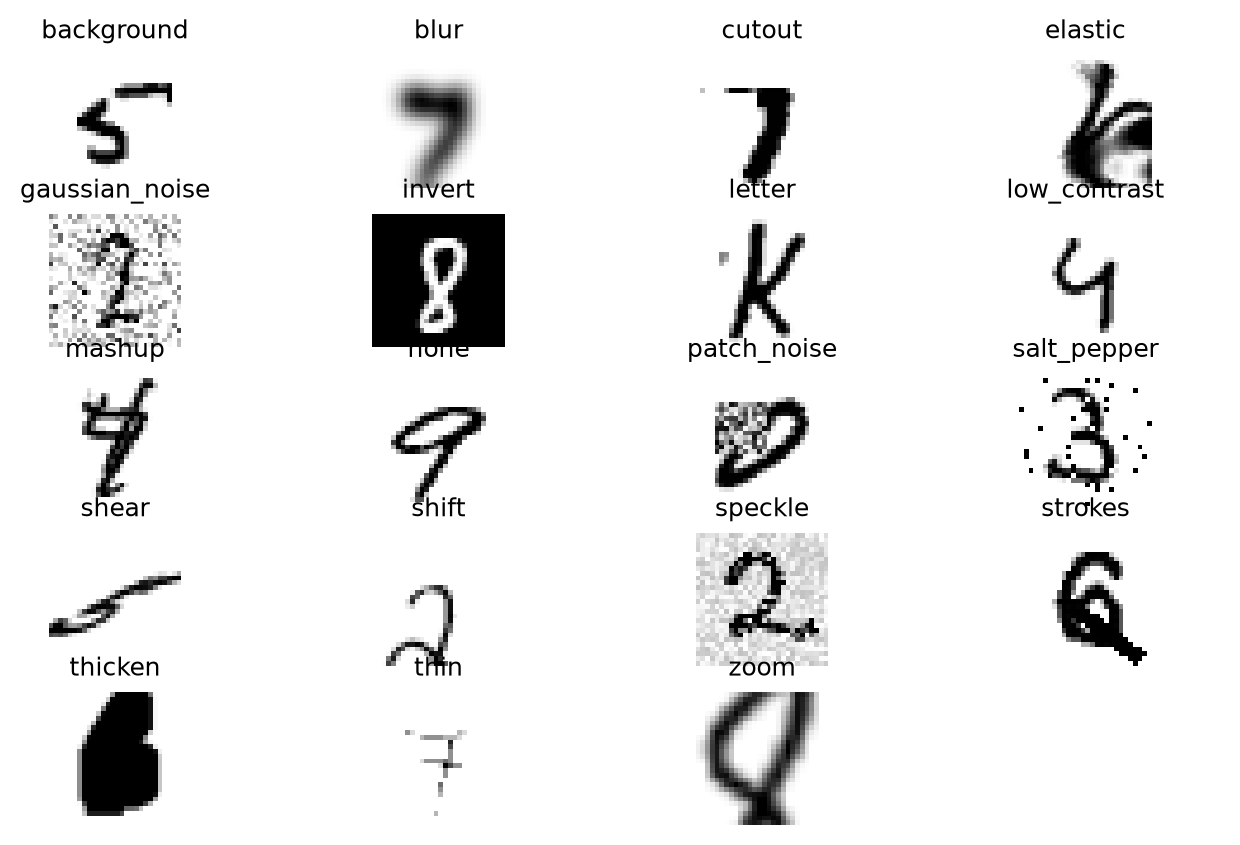

In [28]:
# Let's plot an example of each anomaly type from the validate dataframe.
anomaly_types = sorted(validate_y['anomaly_type'].unique())

fig, axes = plt.subplots(5, 4, figsize=(8, 5))
for ax in axes.flat:
    ax.axis('off')

for ax, anomaly_type in zip(axes.flat, anomaly_types):
    i = np.flatnonzero(validate_y['anomaly_type'] == anomaly_type)[0]
    ax.imshow(validate_X.iloc[i].values.reshape(28, 28), cmap='binary')
    ax.set_title(anomaly_type, fontsize=9)

plt.show()

In [11]:
train_y.iloc[example_id]

digit    8
Name: 1, dtype: int64

In [12]:
# Run this cell to check which PyTorch version and device (GPU or CPU) you are using.
import torch
print('PyTorch version:', torch.__version__)

# Models and tensors will be moved to this device.
# The notebook also runs without a GPU (e.g. on an ml.t3 instance), only slower.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch device:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu')

PyTorch version: 2.14.1+cu126
PyTorch device: NVIDIA A100-SXM4-40GB


In [13]:
# In this variant of the assignment, the model is implemented with plain PyTorch modules,
# and trained with PyTorch Lightning:
# https://docs.pytorch.org/docs/stable/nn.html
# https://lightning.ai/docs/pytorch/stable/

import mlflow
import torch
from torch import nn
import torch.nn.functional as F
import lightning as L


# A LightningModule holds the network together with its training logic:
# the loss function, the logged metrics, and the optimizer.
# It plays the role of Keras' model.compile(...).
class Autoencoder(L.LightningModule):
    def __init__(self, network: nn.Module, learning_rate: float):
        super().__init__()
        self.network = network
        self.learning_rate = learning_rate

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.network(x)

    def training_step(self, batch, batch_idx):
        x, y = batch
        # Using MSE as the loss function.
        loss = F.mse_loss(self(x), y)
        # on_epoch=True averages the loss over the epoch, like Keras' "loss".
        self.log('loss', loss, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        x, y = batch
        loss = F.mse_loss(self(x), y)
        self.log('val_loss', loss, on_step=False, on_epoch=True, prog_bar=True)

    def configure_optimizers(self):
        # Adam optimizer. Other optimizers can also be used.
        return torch.optim.Adam(self.parameters(), lr=self.learning_rate)


def build_model(encoder_width: int, learning_rate_log: float) -> Autoencoder:
    mlflow.log_param('encoder_width', encoder_width)
    mlflow.log_param('learning_rate_log', learning_rate_log)

    # IMPORTANT: This is an example of a very simple undercomplete autoencoder.
    # In other words, you will probably need to tweak these lines of code.

    # nn.Sequential attaches every layer's output to the next layer's input.
    # This is essentially a helper class for any feedforward networks.
    network = nn.Sequential(
        # Input: a flattened 28x28 image (28 * 28 = 784 inputs)
        # Encoder: Gaussian Error Linear Unit activation
        nn.Linear(in_features=28 * 28, out_features=encoder_width),
        nn.GELU(),

        # Decoder: matches the shape of the image
        # Sigmoid activation is needed because pixel
        # values are real numbers between 0 (dark) and 1 (bright).
        nn.Linear(in_features=encoder_width, out_features=28 * 28),
        nn.Sigmoid(),
    )

    # Initialize the weights like Keras does by default: Glorot (Xavier) uniform weights and zero biases.
    # With PyTorch's default initialization, this autoencoder often gets stuck at large learning rates.
    for layer in network:
        if isinstance(layer, nn.Linear):
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)

    return Autoencoder(network, learning_rate=float(10 ** learning_rate_log))

In [14]:
import os
import numpy as np
from torch.utils.data import TensorDataset, DataLoader
from torchinfo import summary


# This function will be used to save each trained model.
def save_model(model: Autoencoder, model_path: str):
    os.makedirs(model_path, exist_ok=True)

    # Export the trained model on the CPU, in evaluation mode
    # (matters for layers such as Dropout or BatchNorm).
    model = model.cpu().eval()

    # torch.export traces the model with an example batch of images.
    # The batch dimension is declared dynamic, so the saved model accepts any number of images.
    example_X = torch.rand(8, 28 * 28)
    exported = torch.export.export(model, (example_X,), dynamic_shapes=({0: torch.export.Dim('batch')},))

    # model.pt2 is self-contained: the computation graph and the trained parameters.
    torch.export.save(exported, f'{model_path}/model.pt2')

    # model_summary.txt -- the layers, output shapes and parameter counts.
    with open(f'{model_path}/model_summary.txt', 'w') as f:
        f.write(str(summary(model, input_size=(1, 28 * 28), device='cpu', verbose=0)))


# This function can be used to load a previously trained model.
# It does not need the Autoencoder class: model.pt2 contains everything.
def load_model(model_path: str) -> nn.Module:
    return torch.export.load(f'{model_path}/model.pt2').module()


# This function runs a model on a dataframe (or NumPy array) of images,
# and returns the outputs as a NumPy array, like Keras' model.predict().
def predict(model: nn.Module, X) -> np.ndarray:
    # .contiguous() stores each image's pixels next to each other in memory (see train_anomaly_model).
    X = torch.tensor(np.asarray(X), dtype=torch.float32).contiguous()

    # Switch a trained Autoencoder to evaluation mode.
    # Models loaded with load_model are already in evaluation mode.
    if isinstance(model, L.LightningModule):
        model.eval()
    model = model.to(device)

    outputs = []
    with torch.no_grad():
        for (batch_X,) in DataLoader(TensorDataset(X), batch_size=1024):
            outputs.append(model(batch_X.to(device)).cpu())
    return torch.cat(outputs).numpy()

In [15]:
# IMPORTANT: This is an example of an autoencoder trained in reconstruction mode
# on the normal images, which uses the reconstruction error as the anomaly score:
# the model only learns to reconstruct normal digits, so it should reconstruct anomalies poorly.
# In other words, you will probably need to tweak these lines of code.
from lightning.pytorch.loggers import MLFlowLogger
import logging
import tempfile
from sklearn.metrics import roc_auc_score
import warnings

# Hide Lightning's informational messages printed at the start of each training
# (the device is already printed by the GPU cell above).
logging.getLogger('lightning.pytorch').setLevel(logging.WARNING)

# Lightning suggests DataLoader worker processes for speed,
# but they are not needed for small datasets that are already in memory.
warnings.filterwarnings('ignore', '.*does not have many workers.*')

# The validation loss is measured on the normal images of the validate dataframe.
validate_normal_X = validate_X[validate_y['is_anomaly'] == 0]


# The anomaly score of each image: the higher, the more likely the image is an anomaly.
def anomaly_score(model: nn.Module, X: pd.DataFrame) -> np.ndarray:
    reconstructed_X = predict(model, X)
    return ((np.asarray(X) - reconstructed_X) ** 2).sum(axis=1)


# Collects the metrics (loss, val_loss) at the end of each epoch,
# like the History object returned by Keras' model.fit(),
# and optionally prints them.
class History(L.Callback):
    def __init__(self, verbose: bool):
        self.verbose = verbose
        self.history = {}

    def on_train_epoch_end(self, trainer, model):
        for name, value in trainer.callback_metrics.items():
            self.history.setdefault(name, []).append(value.item())
        if self.verbose:
            metrics = ' - '.join(f'{name}: {value.item():.4f}' for name, value in sorted(trainer.callback_metrics.items()))
            print(f'Epoch {trainer.current_epoch + 1}/{trainer.max_epochs} - {metrics}')


def train_anomaly_model(model: Autoencoder, epochs: int, verbose: bool = True) -> History:
    # Pandas (and therefore these arrays) store the pixels column by column.
    # .contiguous() stores each image's pixels next to each other in memory,
    # which makes assembling batches of images much faster.
    train_tensor = torch.tensor(train_X.values, dtype=torch.float32).contiguous()
    validate_tensor = torch.tensor(validate_normal_X.values, dtype=torch.float32).contiguous()

    # Each batch is a pair (inputs, targets).
    # In reconstruction mode, the targets are the inputs themselves.
    train_loader = DataLoader(TensorDataset(train_tensor, train_tensor), batch_size=128, shuffle=True, num_workers=0)
    validate_loader = DataLoader(TensorDataset(validate_tensor, validate_tensor), batch_size=128, num_workers=0)

    # Logs the metrics of each epoch to the active MLflow run (see mlflow.start_run() below).
    mlflow_logger = MLFlowLogger(tracking_uri=mlflow.get_tracking_uri(), run_id=mlflow.active_run().info.run_id)
    history = History(verbose)

    trainer = L.Trainer(
        # It's a good idea to have low number of epochs,
        # to test the learning process, but not for the final model training.
        max_epochs=epochs,

        accelerator=device.type,
        devices=1,
        logger=mlflow_logger,
        callbacks=[history],
        # The model is saved below with save_model, so Lightning's checkpoints are not needed.
        enable_checkpointing=False,
        # History prints one line per epoch. Lightning's progress bar
        # updates after every batch, which slows down training in notebooks.
        enable_progress_bar=False,
        enable_model_summary=False,
    )
    trainer.fit(model, train_dataloaders=train_loader, val_dataloaders=validate_loader)

    # Marks the run as a PyTorch model (the Keras variant of this notebook may log to the same experiment).
    mlflow.set_tag('framework', 'pytorch')

    # ROC AUC measures how well the anomaly scores separate anomalies from normal images:
    # 1.0 is perfect separation, 0.5 is random guessing. This is the graded metric.
    mlflow.log_metric('validate_auc', roc_auc_score(validate_y['is_anomaly'], anomaly_score(model, validate_X)))

    # Save model parameters to the file system and upload to MLFlow.
    with tempfile.TemporaryDirectory() as d:
        model_path = f'{d}/model'
        save_model(model, model_path)
        mlflow.log_artifacts(d)

    return history

In [16]:
# See MLFlow docs for more API examples.
# https://mlflow.org/docs/latest/python_api/mlflow.html

import mlflow
mlflow.set_experiment('assignment_01')
# train_anomaly_model logs to MLflow with Lightning's MLFlowLogger, so mlflow.pytorch.autolog() is not needed.

<Experiment: artifact_location='/home/ubuntu/git/ucla-deeplearning/m01_dnn/mlruns/1', creation_time=1792881782121, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792881782121, lifecycle_stage='active', name='assignment_01', tags={}, trace_location=None, workspace='default'>

In [17]:
mlflow.get_experiment_by_name('assignment_01')

<Experiment: artifact_location='/home/ubuntu/git/ucla-deeplearning/m01_dnn/mlruns/1', creation_time=1792881782121, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792881782121, lifecycle_stage='active', name='assignment_01', tags={}, trace_location=None, workspace='default'>

In [18]:
# In order to have reproducible results, we need
# to set the seed values for Python, NumPy, and PyTorch.
# Keep these lines in the same cell as the training code,
# so that you don't accidentally train multiples models
# without reseting the seed.

import lightning as L

L.seed_everything(11)

with mlflow.start_run():
    autoencoder = build_model(encoder_width=10, learning_rate_log=0)
    history = train_anomaly_model(autoencoder, epochs=10)

Seed set to 11
/home/ubuntu/git/ucla-deeplearning/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Epoch 1/10 - loss: 0.1947 - val_loss: 0.1732
Epoch 2/10 - loss: 0.1724 - val_loss: 0.1732
Epoch 3/10 - loss: 0.1724 - val_loss: 0.1732
Epoch 4/10 - loss: 0.1724 - val_loss: 0.1732
Epoch 5/10 - loss: 0.1724 - val_loss: 0.1732
Epoch 6/10 - loss: 0.1724 - val_loss: 0.1732
Epoch 7/10 - loss: 0.1724 - val_loss: 0.1732
Epoch 8/10 - loss: 0.1724 - val_loss: 0.1732
Epoch 9/10 - loss: 0.1724 - val_loss: 0.1732
Epoch 10/10 - loss: 0.1724 - val_loss: 0.1732


In [19]:
# torchinfo shows the layers, their output shapes and number of parameters
# (this is also saved as model_summary.txt by save_model).
summary(autoencoder, input_size=(1, 28 * 28), device='cpu')

Layer (type:depth-idx)                   Output Shape              Param #
Autoencoder                              [1, 784]                  --
├─Sequential: 1-1                        [1, 784]                  --
│    └─Linear: 2-1                       [1, 10]                   7,850
│    └─GELU: 2-2                         [1, 10]                   --
│    └─Linear: 2-3                       [1, 784]                  8,624
│    └─Sigmoid: 2-4                      [1, 784]                  --
Total params: 16,474
Trainable params: 16,474
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.02
Input size (MB): 0.00
Forward/backward pass size (MB): 0.01
Params size (MB): 0.07
Estimated Total Size (MB): 0.08

In [20]:
validate_scores = anomaly_score(autoencoder, validate_X)
roc_auc_score(validate_y['is_anomaly'], validate_scores)

0.5823044353741497

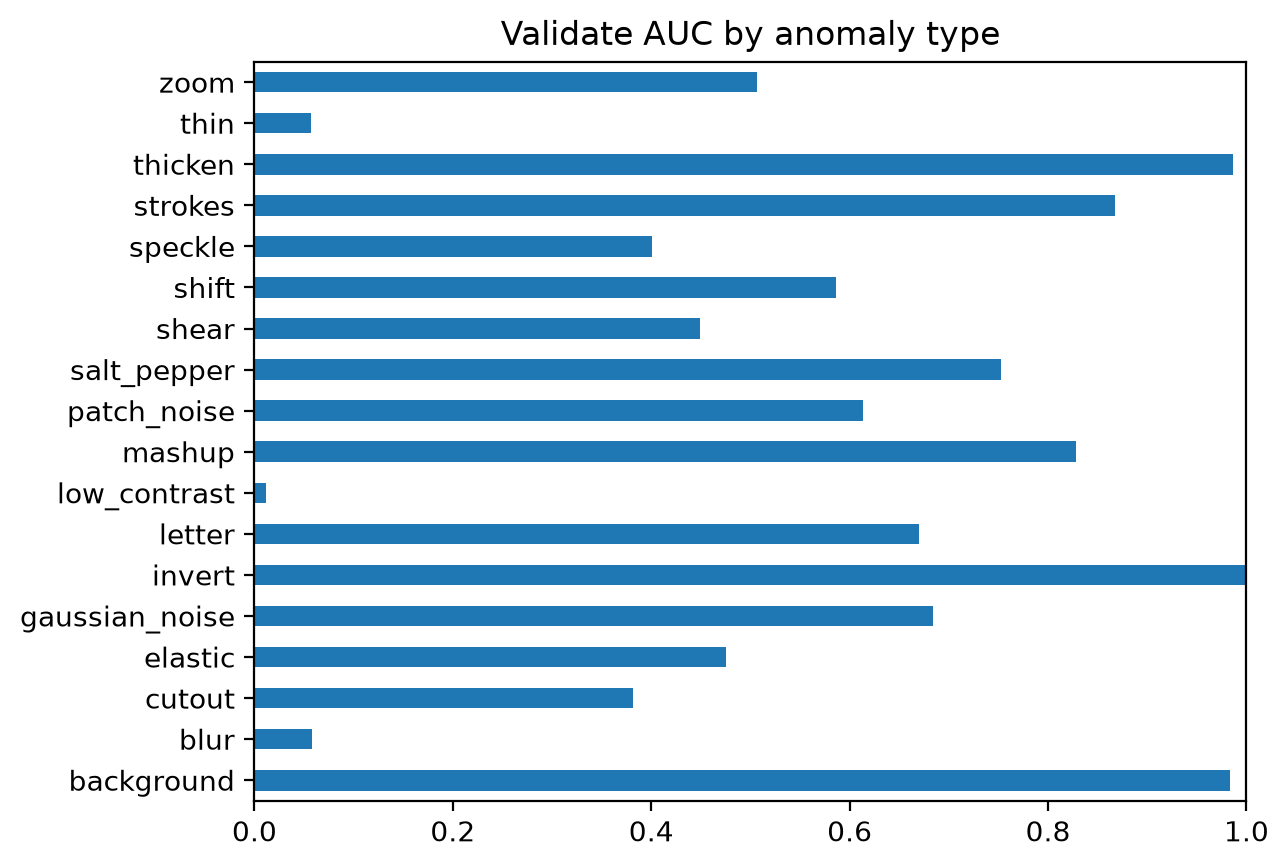

In [21]:
# The AUC of each anomaly type: images of that anomaly type against all normal images.
# This shows which anomalies the model detects well, and which ones it misses.
# An AUC of 0.5 is no better than random guessing, and an AUC below 0.5 means
# that the model scores these anomalies as *more normal* than the normal images.
def auc_by_anomaly_type(y: pd.DataFrame, scores: np.ndarray) -> pd.Series:
    normal = (y['is_anomaly'] == 0).values
    result = {}
    for anomaly_type in sorted(y.loc[~normal, 'anomaly_type'].unique()):
        mask = normal | (y['anomaly_type'] == anomaly_type).values
        result[anomaly_type] = roc_auc_score(y['is_anomaly'][mask], scores[mask])
    return pd.Series(result)

auc_by_anomaly_type(validate_y, validate_scores).plot.barh(title='Validate AUC by anomaly type', xlim=(0, 1))
plt.show()

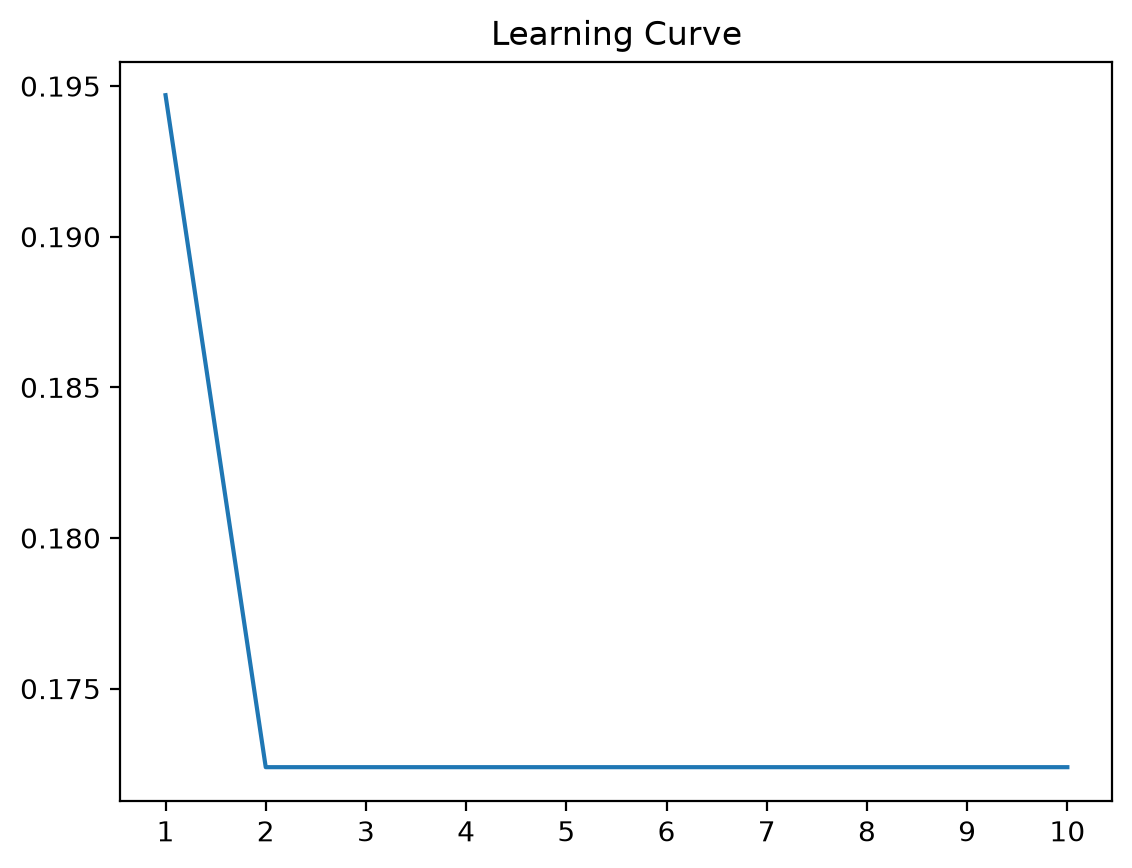

In [22]:
# The History callback collected the loss of each epoch,
# which can be used to plot the learning curve.

learning_curve = pd.Series(history.history['loss'])
learning_curve.index = learning_curve.index + 1

learning_curve.plot(title='Learning Curve')
plt.xticks(learning_curve.index)
plt.show()

In [23]:
import random
import tqdm

runs = 10
learning_rate_logs = [random.uniform(-5, 0) for _ in range(runs)]
encoder_widths = [random.choice(range(5, 20, 5)) for _ in range(runs)]
parameters = list(zip(learning_rate_logs, encoder_widths))

for (learning_rate_log, encoder_width) in tqdm.tqdm(parameters):
    with mlflow.start_run():
        autoencoder = build_model(encoder_width=encoder_width, learning_rate_log=learning_rate_log)
        history = train_anomaly_model(autoencoder, epochs=10, verbose=False)

100%|██████████| 10/10 [02:03<00:00, 12.34s/it]


In [24]:
# This loads the run with the best validate AUC in the experiment (among the runs of this notebook).
best_run = mlflow.search_runs(filter_string="tags.framework = 'pytorch'", order_by=['metrics.validate_auc DESC'], max_results=1).iloc[0]
print('Best run:', best_run['run_id'], 'validate AUC:', best_run['metrics.validate_auc'])
saved_model_path = mlflow.tracking.MlflowClient().download_artifacts(best_run['run_id'], 'model')
autoencoder = load_model(saved_model_path)

Best run: 21bbe350affa4db5acaeb84e4b11f594 validate AUC: 0.8671601088435374


In [25]:
# Once you have selected the final model on the validate dataframe,
# measure its performance on the test dataframe, which was not used to select it.
# Don't let a model that overfits the validate dataframe fool you into using it for the graded submission!
test_scores = anomaly_score(autoencoder, test_X)
roc_auc_score(test_y['is_anomaly'], test_scores)

0.8652753197278911

In [26]:
import os
import shutil

model_path = 'assignment_submission'

os.makedirs(model_path, exist_ok=True)

# Once you are ready to make the graded submission,
# calculate the anomaly scores of the score dataframe.
# Higher score means more likely to be an anomaly, and the rows must stay in the same order as score_X.
score_anomaly_score = pd.DataFrame({'anomaly_score': anomaly_score(autoencoder, score_X)})

# Now save it to disc as a Parquet file.
score_anomaly_score.to_parquet(f'{model_path}/score_anomaly_score.parquet')

# Copy the model files of the run loaded above from MLflow (model.pt2 and model_summary.txt).
# If instead `autoencoder` is a model that you trained in this session (an Autoencoder object),
# save it with: save_model(autoencoder, model_path)
shutil.copytree(saved_model_path, model_path, dirs_exist_ok=True)

# You now have the following files to be uploaded:
# 1. This notebook and any other Python code you used to train the final model.
# 2. model.pt2 -- the exported model: its definition and trained parameters
# 3. model_summary.txt -- the model's layers and parameter counts
# 4. score_anomaly_score.parquet - the model's anomaly scores on the score dataset

'assignment_submission'

In [27]:
# Check that the submitted model.pt2 reproduces the submitted anomaly scores.
# This is also how the model can be loaded by anyone, e.g. a grader:
# no Autoencoder class or training code is needed, and it runs on the CPU.
submitted_model = torch.export.load(f'{model_path}/model.pt2').module()

with torch.no_grad():
    submitted_X = submitted_model(torch.tensor(score_X.values, dtype=torch.float32)).numpy()
submitted_scores = ((score_X.values - submitted_X) ** 2).sum(axis=1)

print(open(f'{model_path}/model_summary.txt').read())
print('Max absolute difference:', np.abs(submitted_scores - score_anomaly_score['anomaly_score'].values).max())
assert np.allclose(submitted_scores, score_anomaly_score['anomaly_score'].values, atol=1e-4), 'model.pt2 does not match score_anomaly_score.parquet'

Layer (type:depth-idx)                   Output Shape              Param #
Autoencoder                              [1, 784]                  --
├─Sequential: 1-1                        [1, 784]                  --
│    └─Linear: 2-1                       [1, 15]                   11,775
│    └─GELU: 2-2                         [1, 15]                   --
│    └─Linear: 2-3                       [1, 784]                  12,544
│    └─Sigmoid: 2-4                      [1, 784]                  --
Total params: 24,319
Trainable params: 24,319
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.02
Input size (MB): 0.00
Forward/backward pass size (MB): 0.01
Params size (MB): 0.10
Estimated Total Size (MB): 0.11
Max absolute difference: 0.00012207031
